# 🔬 Research Proposal: Volatility-Adaptive Merit-Based Sortition (VAMS)
## *Optimizing Decentralized Network Efficiency via Adaptive Replacement Rate Control*

---

## Background
Merit-based sortition, as proposed by Kruijssen et al. (2024) [1], selects an active subset of participants in a decentralized network based on an Exponential Moving Average (EMA) of their quality scores. The replacement percentile **P** governs how many active participants are eligible to be replaced each epoch. Kruijssen et al. (2024) [1] treat P as a fixed hyperparameter and show that P ∈ [20%, 40%] yields statistically significant improvements over random sortition.

## Problem Statement
A fixed P is suboptimal in non-stationary environments where participant performance volatility varies over time. This study proposes that P should dynamically adapt to the current state of the network.

## Proposed Formula (VAMS)
$$P_t = P_{\min} + (P_{\max} - P_{\min}) \cdot \sigma\!\left(k \cdot (\sigma_{A,t-1} - \sigma_{\text{ref}})\right)$$

| Symbol | Value | Description |
|--------|-------|-------------|
| $P_{\min}$ | 10% | Lower bound on replacement rate |
| $P_{\max}$ | 40% | Upper bound on replacement rate |
| $k$ | 20 | Sigmoid steepness (sensitivity) |
| $W$ | 50 | Rolling window for $\sigma_{\text{ref}}$ |
| $\sigma_{A,t-1}$ | — | Std of active set quality scores at $t{-}1$ |
| $\sigma_{\text{ref}}$ | — | Rolling mean of $\sigma_A$ over last $W$ epochs |

**Adaptive Logic:**
- 📉 **Low volatility** → stable network → lower $P_t$ → protect high performers
- 📈 **High volatility** → unstable network → higher $P_t$ → explore inactive pool faster

---

## Notebook Structure
| Section | Content |
|---------|--------|
| **1** | Imports & Setup |
| **2** | Simulation Engine (3 modes: random / static / adaptive) |
| **3** | Figure A — Main Comparison (quality over time) |
| **4** | Figure B — Confidence Intervals & Error Bands |
| **5** | Figure C — Statistical Significance (t-tests) |
| **6** | Figure D — Convergence Speed Analysis |
| **7** | Figure E — EMA Sensitivity Analysis (effect of α) |
| **8** | Figure F — Sensitivity Heatmap (k vs W) |
| **9** | Figure G — Volatility Shock Response |
| **10** | Complete Results Table |

---
**Reference:** [1] Kruijssen, J. M. D., Valieva, R., Peluso, K., Emmons, N., & Longmore, S. N. (2024). Merit-Based Sortition in Decentralized Systems. *Allora Decentralized Intelligence*, 1, 20–27. doi:10.70235/allora.0x10020

## 1️⃣ Imports & Setup

In [2]:
# Uncomment if needed:
# !pip install numpy matplotlib scipy

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
from scipy.special import expit          # numerically stable sigmoid
from scipy import stats                  # t-tests, confidence intervals
from collections import deque
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams['figure.dpi']   = 120
plt.rcParams['font.size']    = 10
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

# ── Experiment constants ──────────────────────────────────────────────────
SEEDS    = [42, 7, 13, 99, 21, 3, 17, 88, 55, 31]   # 10 seeds for robust CI
NEPOCHS  = 1000
CI_LEVEL = 0.95                                      # confidence level

# Four pool scenarios from Kruijssen et al. (2024) [1]
SCENARIOS = [
    dict(label='Fixed Pool',     Ninit=80,  Nact=50, pgrowth=1e-10, pattr=1e-10),
    dict(label='Growing Pool',   Ninit=8,   Nact=32, pgrowth=0.1,   pattr=1e-10),
    dict(label='Shrinking Pool', Ninit=100, Nact=32, pgrowth=1e-10, pattr=2e-3),
    dict(label='Evolving Pool',  Ninit=100, Nact=32, pgrowth=0.1,   pattr=2e-3),
]

print(f'Setup complete. Using {len(SEEDS)} seeds × {len(SCENARIOS)} scenarios.')
print(f'Confidence level: {CI_LEVEL*100:.0f}%')

Setup complete. Using 10 seeds × 4 scenarios.
Confidence level: 95%


## 2️⃣ Simulation Engine
Implements three modes in a single function:
- `'random'` — Classical random sortition baseline (Kruijssen et al., 2024 [1])
- `'static'` — Merit-based sortition with fixed P (Kruijssen et al., 2024 [1])
- `'adaptive'` — **VAMS** (proposed in this study)

In [3]:
def run_sortition(
    Ninit, Nact, Nepochs=1000,
    mu_Q=0.2, sigma_Q=0.1, V=0.2, alpha=0.1,
    pgrowth=1e-10, pattr=1e-10,
    mode='static',
    P_static=25.0,
    P_min=10.0, P_max=40.0, k=20.0, window=50,
    seed=42,
):
    """
    Unified merit-based sortition simulation.
    Implements Equations 1-4 from Kruijssen et al. (2024) [1].

    Parameters
    ----------
    mode : 'random' | 'static' | 'adaptive'
    
    Returns
    -------
    mean_T    : (Nepochs,) mean instantaneous quality of active set
    P_history : (Nepochs,) P_t value used per epoch
    sigma_history : (Nepochs,) sigma_A per epoch
    """
    rng        = np.random.default_rng(seed)
    lambda_pen = 2.0

    n        = Ninit
    Q_med    = rng.normal(mu_Q, sigma_Q, n)
    Q_ema    = np.full(n, np.nan)
    active   = np.zeros(n, dtype=bool)
    alive    = np.ones(n,  dtype=bool)
    p_safe   = max(pattr, 1e-15)
    lifetime = rng.geometric(p_safe, n) if pattr > 0 else np.full(n, 10**8)

    mean_T        = []
    P_history     = []
    sigma_history = []
    sigma_buf     = deque(maxlen=window)

    idx_alive = np.where(alive)[0]
    active[rng.choice(idx_alive, size=min(Nact, len(idx_alive)), replace=False)] = True

    for i in range(Nepochs):
        idx_alive = np.where(alive)[0]
        if len(idx_alive) == 0:
            mean_T.append(np.nan); P_history.append(np.nan); sigma_history.append(np.nan)
            continue

        T = np.full(n, np.nan)
        for j in idx_alive:
            if active[j]:
                T[j] = rng.normal(Q_med[j], V)

        T_act = T[active & alive]
        T_act = T_act[~np.isnan(T_act)]
        if len(T_act) == 0:
            mean_T.append(np.nan); P_history.append(np.nan); sigma_history.append(np.nan)
            continue

        min_T = float(np.min(T_act))
        std_T = float(np.std(T_act)) if len(T_act) > 1 else 0.0
        sigma_history.append(std_T)

        # ── Determine P_t ─────────────────────────────────────────────────
        if mode == 'random':
            P_t = 25.0
        elif mode == 'static':
            P_t = P_static
        elif mode == 'adaptive':
            sigma_buf.append(std_T)
            sigma_ref = float(np.mean(sigma_buf))
            # VAMS sigmoid formula (proposed in this study)
            P_t = P_min + (P_max - P_min) * float(expit(k * (std_T - sigma_ref)))

        P_history.append(P_t)
        target_inactive = float(np.percentile(T_act, P_t))

        # ── EMA update: Equations 1-4 of Kruijssen et al. (2024) [1] ──────
        for j in idx_alive:
            if mode != 'random':
                if active[j]:
                    hat_Q = (min_T - lambda_pen * std_T) if np.isnan(T[j]) else T[j]
                else:
                    hat_Q = target_inactive
                Q_ema[j] = hat_Q if np.isnan(Q_ema[j]) else alpha * hat_Q + (1-alpha) * Q_ema[j]

        # ── Select active set ──────────────────────────────────────────────
        if mode == 'random':
            new_active = set(rng.choice(idx_alive, size=min(Nact, len(idx_alive)), replace=False).tolist())
        else:
            ema_v = Q_ema[idx_alive]; valid = ~np.isnan(ema_v); v_idx = idx_alive[valid]
            if len(v_idx) <= Nact:
                new_active = set(v_idx.tolist())
                no_e = idx_alive[~valid].tolist()
                need = Nact - len(new_active)
                if need > 0 and no_e:
                    new_active.update(rng.choice(no_e, size=min(need, len(no_e)), replace=False).tolist())
            else:
                sd  = v_idx[np.argsort(ema_v[valid])[::-1]]
                cut = Q_ema[sd[Nact-1]]
                ab  = [j for j in sd[:Nact] if Q_ema[j] > cut]
                ti  = [j for j in v_idx if Q_ema[j] == cut]
                nd  = Nact - len(ab)
                if nd > 0 and ti:
                    ab += rng.choice(ti, size=min(nd, len(ti)), replace=False).tolist()
                new_active = set(ab)

        active[:] = False
        for j in new_active: active[j] = True

        T_rec = [T[j] if not np.isnan(T[j]) else rng.normal(Q_med[j], V) for j in new_active]
        mean_T.append(float(np.mean(T_rec)) if T_rec else np.nan)

        for j in idx_alive:
            lifetime[j] -= 1
            if lifetime[j] <= 0: alive[j] = False; active[j] = False

        n_new = rng.poisson(pgrowth)
        if n_new > 0:
            Q_med    = np.concatenate([Q_med,    rng.normal(mu_Q, sigma_Q, n_new)])
            Q_ema    = np.concatenate([Q_ema,    np.full(n_new, target_inactive)])
            alive    = np.concatenate([alive,    np.ones(n_new,  dtype=bool)])
            active   = np.concatenate([active,   np.zeros(n_new, dtype=bool)])
            lifetime = np.concatenate([lifetime, rng.geometric(p_safe, n_new) if pattr > 0 else np.full(n_new, 10**8)])
            n = len(Q_med)

    return np.array(mean_T), np.array(P_history), np.array(sigma_history)


# ── Utility functions ─────────────────────────────────────────────────────
def ema_smooth(x, alpha=0.05):
    out = np.empty_like(x, dtype=float)
    x   = np.where(np.isnan(x), 0, x)
    out[0] = x[0]
    for i in range(1, len(x)):
        out[i] = alpha * x[i] + (1-alpha) * out[i-1]
    return out


def multi_seed_run(mode, sc, seeds, **kwargs):
    """Run across multiple seeds. Returns arrays: T_all, P_all, S_all per seed."""
    T_runs, P_runs, S_runs = [], [], []
    for s in seeds:
        mt, ph, sh = run_sortition(**sc, mode=mode, seed=s, **kwargs)
        T_runs.append(mt); P_runs.append(ph); S_runs.append(sh)
    return np.array(T_runs), np.array(P_runs), np.array(S_runs)


def confidence_band(runs, level=0.95):
    """Return (mean, lower_CI, upper_CI) across seed dimension."""
    n      = runs.shape[0]
    mean   = np.nanmean(runs, axis=0)
    se     = np.nanstd(runs,  axis=0) / np.sqrt(n)
    t_crit = stats.t.ppf((1 + level) / 2, df=n-1)
    return mean, mean - t_crit * se, mean + t_crit * se


def welch_t_test(runs_a, runs_b):
    """Welch's t-test between two sets of per-seed mean quality values."""
    means_a = np.nanmean(runs_a, axis=1)   # one scalar per seed
    means_b = np.nanmean(runs_b, axis=1)
    t_stat, p_val = stats.ttest_ind(means_a, means_b, equal_var=False)
    cohen_d = (np.mean(means_a) - np.mean(means_b)) / np.sqrt(
        (np.std(means_a)**2 + np.std(means_b)**2) / 2
    )
    return t_stat, p_val, cohen_d


def convergence_epoch(mean_T, threshold_frac=0.95):
    """
    Return the first epoch at which the smoothed quality metric
    reaches threshold_frac of its final value (last 100 epoch mean).
    """
    sm     = ema_smooth(mean_T, alpha=0.05)
    target = threshold_frac * np.nanmean(sm[-100:])
    idxs   = np.where(sm >= target)[0]
    return int(idxs[0]) if len(idxs) > 0 else len(mean_T)


print('Simulation engine ready ✓')
print('Utility functions: multi_seed_run, confidence_band, welch_t_test, convergence_epoch')

Simulation engine ready ✓
Utility functions: multi_seed_run, confidence_band, welch_t_test, convergence_epoch


## 3️⃣ Figure A — Main Comparison
Mean instantaneous quality of the active set over 1000 epochs, averaged across 10 random seeds.
Compares random sortition [1], static P=25% [1], and the proposed VAMS.

> ⏱️ ~3–4 minutes

Running Figure A: Main quality comparison...
  Running Fixed Pool...
  Running Growing Pool...
  Running Shrinking Pool...
  Running Evolving Pool...


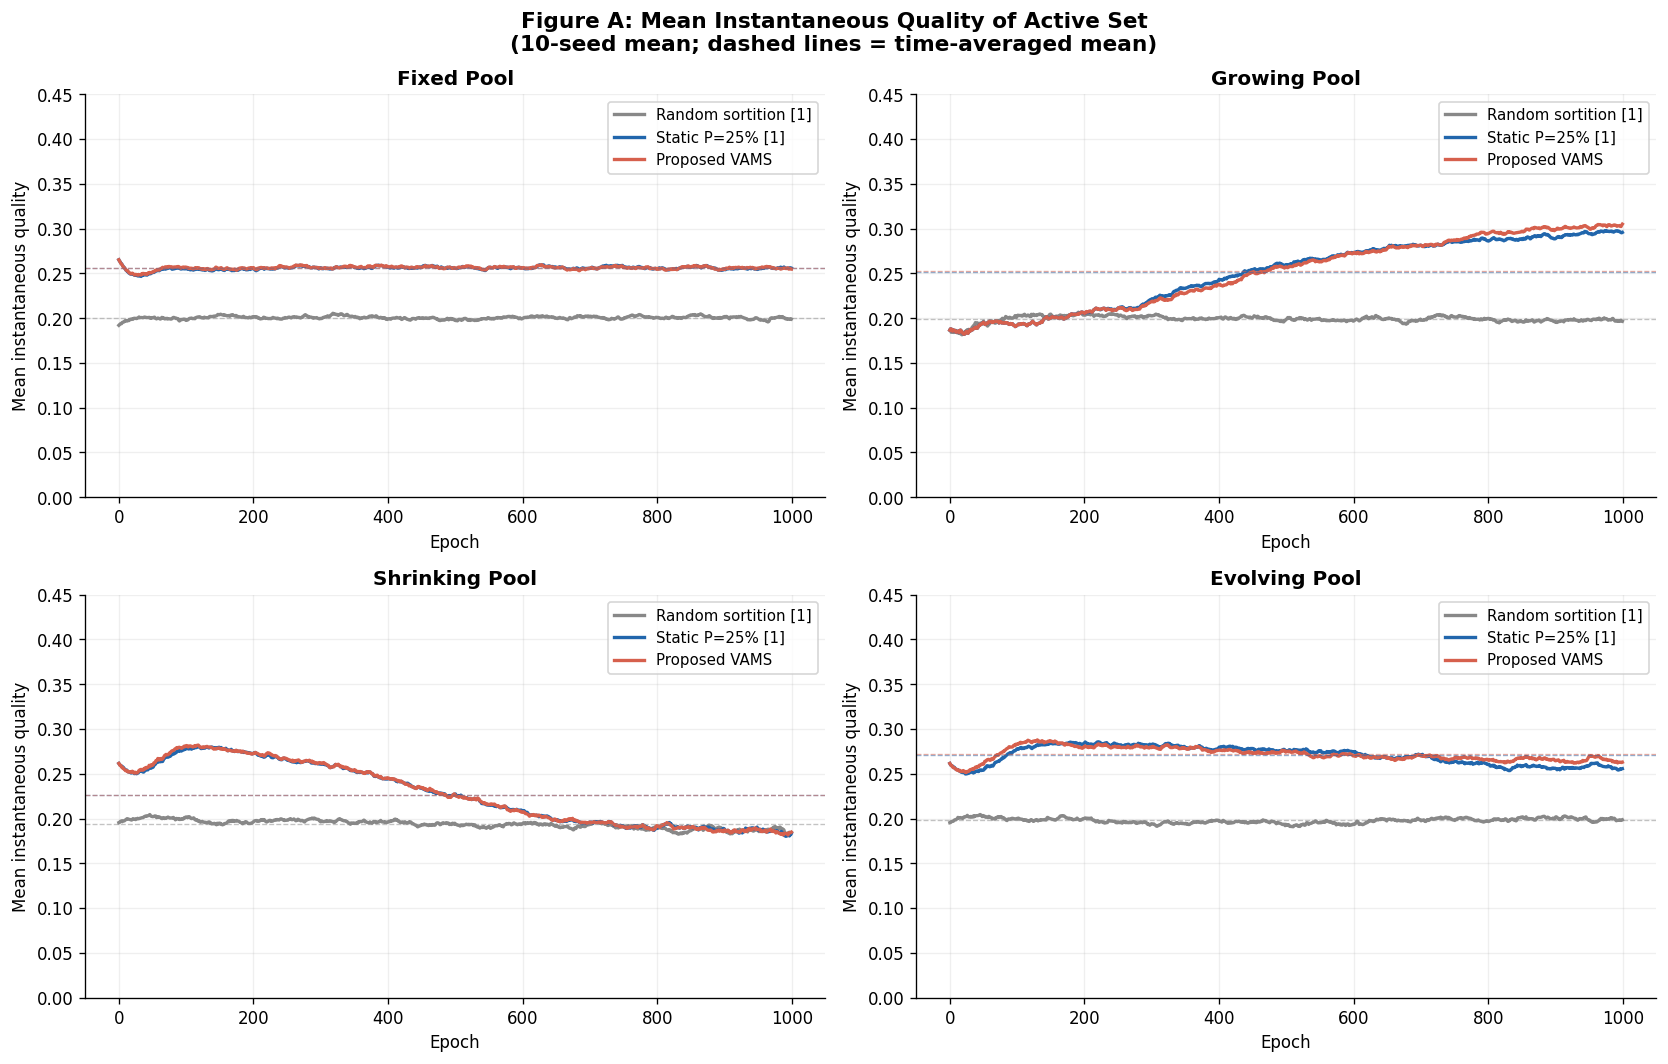

Figure A saved ✓


In [4]:
print('Running Figure A: Main quality comparison...')

# Collect all results here for reuse in later cells
ALL_RESULTS = {}

for sc_raw in SCENARIOS:
    sc    = {k: v for k, v in sc_raw.items() if k != 'label'}
    sc['Nepochs'] = NEPOCHS
    label = sc_raw['label']
    print(f'  Running {label}...')

    T_rand,   P_rand,   S_rand   = multi_seed_run('random',   sc, SEEDS)
    T_static, P_static, S_static = multi_seed_run('static',   sc, SEEDS, P_static=25.0)
    T_adapt,  P_adapt,  S_adapt  = multi_seed_run('adaptive', sc, SEEDS,
                                                   P_min=10, P_max=40, k=20, window=50)
    ALL_RESULTS[label] = {
        'T_rand': T_rand, 'T_static': T_static, 'T_adapt': T_adapt,
        'P_adapt': P_adapt, 'S_adapt': S_adapt,
        'sc': sc
    }

fig_A, axes_A = plt.subplots(2, 2, figsize=(14, 9))
axes_A = axes_A.flatten()
COLORS = {'random': '#888888', 'static': '#2166ac', 'adapt': '#d6604d'}

for idx, sc_raw in enumerate(SCENARIOS):
    label = sc_raw['label']
    R     = ALL_RESULTS[label]
    ax    = axes_A[idx]
    epochs = np.arange(NEPOCHS)

    for key, T_runs, color, lbl in [
        ('random', R['T_rand'],   COLORS['random'], 'Random sortition [1]'),
        ('static', R['T_static'], COLORS['static'], 'Static P=25% [1]'),
        ('adapt',  R['T_adapt'],  COLORS['adapt'],  'Proposed VAMS'),
    ]:
        mean_T = np.nanmean(T_runs, axis=0)
        ax.plot(epochs, ema_smooth(mean_T), color=color, lw=2.0, label=lbl)

    ax.set_title(label, fontweight='bold', fontsize=12)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Mean instantaneous quality')
    ax.set_ylim(0, 0.45); ax.legend(fontsize=9); ax.grid(True, alpha=0.2)

    # Annotate means
    for T_runs, color, offset in [
        (R['T_rand'],   COLORS['random'], 0.01),
        (R['T_static'], COLORS['static'], 0.04),
        (R['T_adapt'],  COLORS['adapt'],  0.07),
    ]:
        mu = np.nanmean(T_runs)
        ax.axhline(mu, color=color, ls='--', lw=0.8, alpha=0.5)

fig_A.suptitle(
    'Figure A: Mean Instantaneous Quality of Active Set\n'
    '(10-seed mean; dashed lines = time-averaged mean)',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
plt.savefig('figA_main_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure A saved ✓')

## 4️⃣ Figure B — Confidence Intervals & Error Bands
95% confidence intervals computed across 10 seeds using Student's t-distribution.
Wider bands indicate higher variability across seeds (less stable method).

Running Figure B: Confidence interval bands...


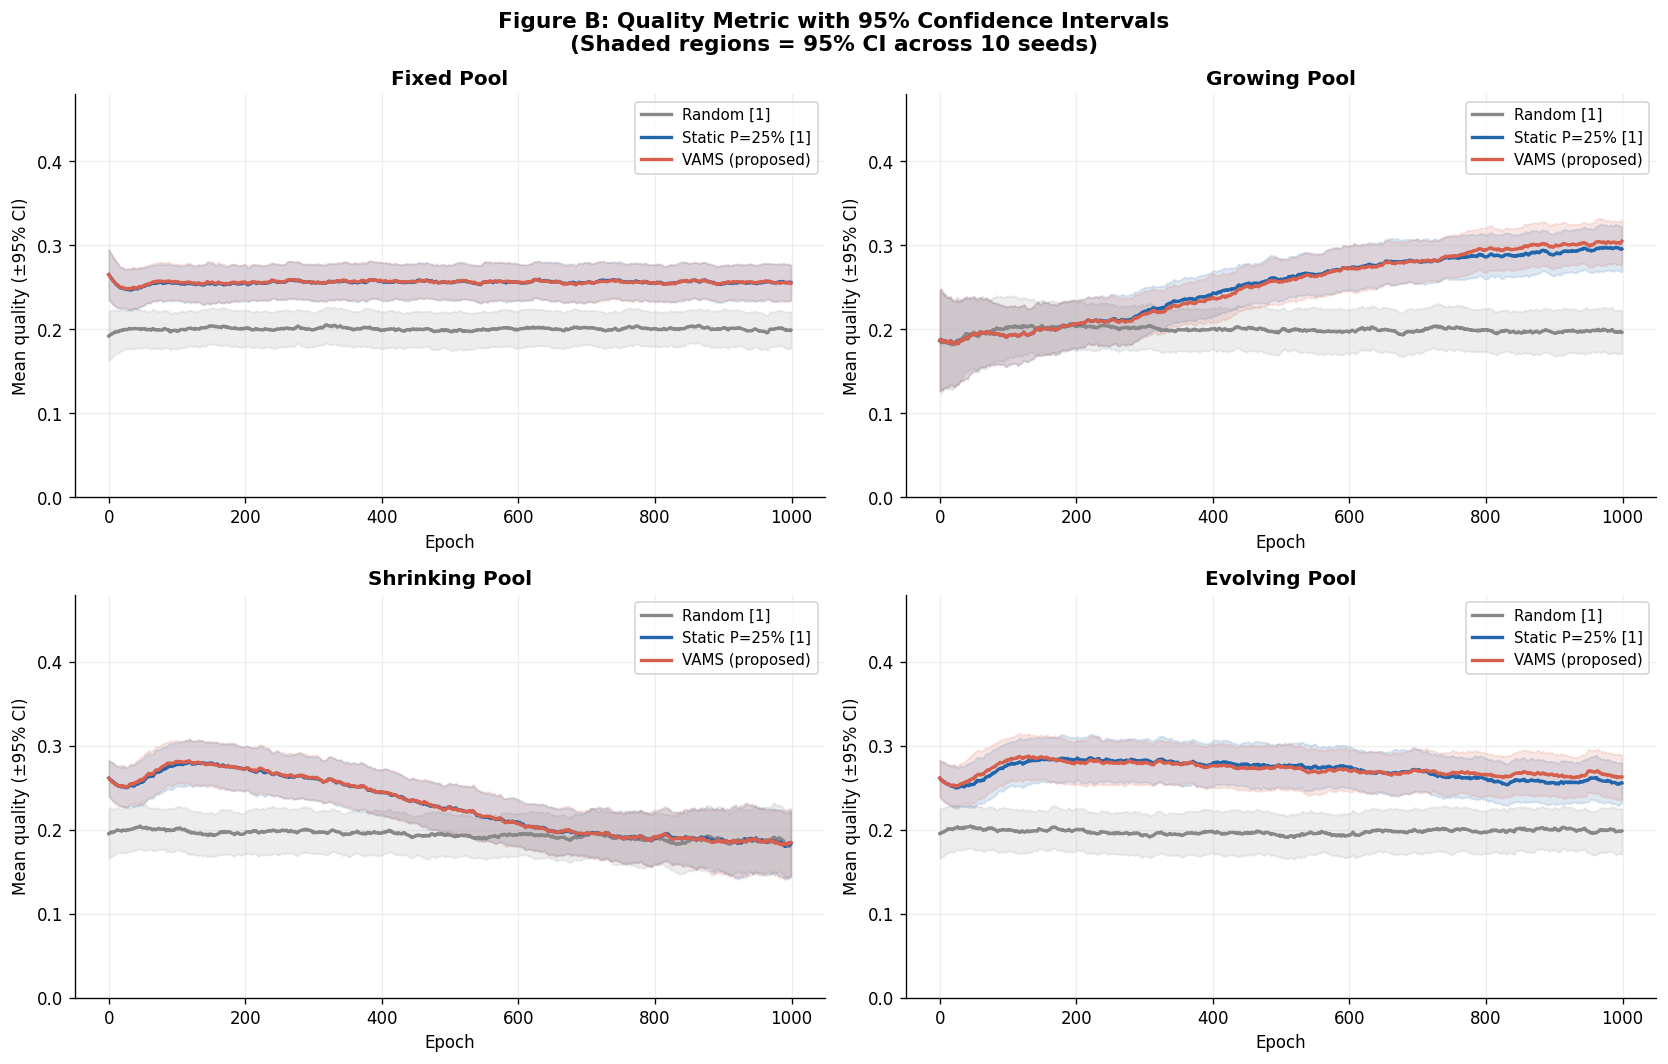

Figure B saved ✓

Interpretation:
  Narrower CI bands = more reproducible / stable behaviour across seeds.
  Overlap between VAMS and Static CI bands signals no significant difference there.


In [5]:
print('Running Figure B: Confidence interval bands...')

fig_B, axes_B = plt.subplots(2, 2, figsize=(14, 9))
axes_B = axes_B.flatten()

for idx, sc_raw in enumerate(SCENARIOS):
    label = sc_raw['label']
    R     = ALL_RESULTS[label]
    ax    = axes_B[idx]
    epochs = np.arange(NEPOCHS)

    for T_runs, color, lbl in [
        (R['T_rand'],   COLORS['random'], 'Random [1]'),
        (R['T_static'], COLORS['static'], 'Static P=25% [1]'),
        (R['T_adapt'],  COLORS['adapt'],  'VAMS (proposed)'),
    ]:
        mean_s, lo, hi = confidence_band(T_runs, level=CI_LEVEL)
        ax.plot(epochs, ema_smooth(mean_s), color=color, lw=2.0, label=lbl)
        ax.fill_between(epochs,
                        ema_smooth(lo), ema_smooth(hi),
                        color=color, alpha=0.15)

    ax.set_title(f'{label}', fontweight='bold', fontsize=12)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Mean quality (±95% CI)')
    ax.set_ylim(0, 0.48); ax.legend(fontsize=9); ax.grid(True, alpha=0.2)

fig_B.suptitle(
    'Figure B: Quality Metric with 95% Confidence Intervals\n'
    '(Shaded regions = 95% CI across 10 seeds)',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
plt.savefig('figB_confidence_intervals.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure B saved ✓')
print()
print('Interpretation:')
print('  Narrower CI bands = more reproducible / stable behaviour across seeds.')
print('  Overlap between VAMS and Static CI bands signals no significant difference there.')

## 5️⃣ Figure C — Statistical Significance (Welch's t-tests)
Welch's t-test (unequal variance) tests whether the difference in mean quality between VAMS and Static P is statistically significant across seeds.

Cohen's d measures **practical significance** (effect size):
- d < 0.2: negligible effect
- d ∈ [0.2, 0.5): small effect
- d ∈ [0.5, 0.8): medium effect
- d ≥ 0.8: large effect

Running Figure C: Statistical significance tests...


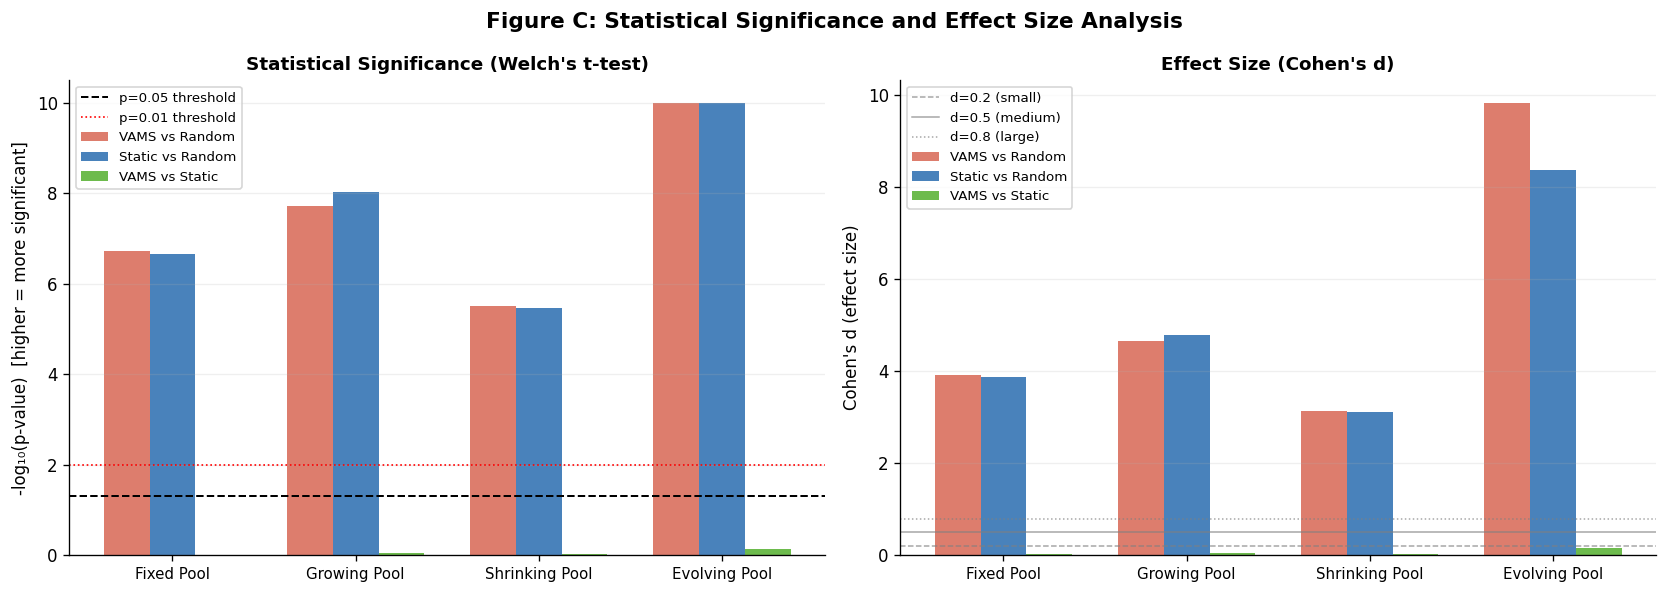


Scenario           Comparison               t-stat    p-value  Cohen's d   Sig
---------------------------------------------------------------------------
Fixed Pool         VAMS vs Random            8.295     0.0000     3.9103   ***
Fixed Pool         Static vs Random          8.220     0.0000     3.8751   ***
Fixed Pool         VAMS vs Static            0.041     0.9681     0.0191    ns

Growing Pool       VAMS vs Random            9.861     0.0000     4.6487   ***
Growing Pool       Static vs Random         10.149     0.0000     4.7841   ***
Growing Pool       VAMS vs Static            0.125     0.9022     0.0587    ns

Shrinking Pool     VAMS vs Random            6.655     0.0000     3.1371   ***
Shrinking Pool     Static vs Random          6.602     0.0000     3.1123   ***
Shrinking Pool     VAMS vs Static            0.065     0.9493     0.0304    ns

Evolving Pool      VAMS vs Random           20.863     0.0000     9.8351   ***
Evolving Pool      Static vs Random         17.747 

In [6]:
print('Running Figure C: Statistical significance tests...')

comparisons = [
    ('VAMS vs Random',  'T_adapt',  'T_rand'),
    ('Static vs Random','T_static', 'T_rand'),
    ('VAMS vs Static',  'T_adapt',  'T_static'),
]

stat_results = {}
for sc_raw in SCENARIOS:
    label = sc_raw['label']
    R     = ALL_RESULTS[label]
    stat_results[label] = {}
    for comp_label, key_a, key_b in comparisons:
        t, p, d = welch_t_test(R[key_a], R[key_b])
        stat_results[label][comp_label] = (t, p, d)

# ── Plot p-values and Cohen's d ───────────────────────────────────────────
fig_C, (cx1, cx2) = plt.subplots(1, 2, figsize=(14, 5))

sc_names   = [s['label'] for s in SCENARIOS]
comp_names = [c[0] for c in comparisons]
bar_colors = ['#d6604d', '#2166ac', '#4dac26']
x          = np.arange(len(sc_names))
width      = 0.25

# p-values (log scale)
for ci, comp in enumerate(comp_names):
    p_vals = [-np.log10(max(stat_results[sc][comp][1], 1e-10)) for sc in sc_names]
    cx1.bar(x + ci*width, p_vals, width, color=bar_colors[ci], alpha=0.82, label=comp)
cx1.axhline(-np.log10(0.05), color='black', ls='--', lw=1.2, label='p=0.05 threshold')
cx1.axhline(-np.log10(0.01), color='red',   ls=':',  lw=1.0, label='p=0.01 threshold')
cx1.set_xticks(x + width); cx1.set_xticklabels(sc_names, fontsize=9)
cx1.set_ylabel('-log₁₀(p-value)  [higher = more significant]', fontsize=10)
cx1.set_title('Statistical Significance (Welch\'s t-test)', fontsize=11, fontweight='bold')
cx1.legend(fontsize=8); cx1.grid(True, alpha=0.2, axis='y')

# Cohen's d
for ci, comp in enumerate(comp_names):
    d_vals = [stat_results[sc][comp][2] for sc in sc_names]
    cx2.bar(x + ci*width, d_vals, width, color=bar_colors[ci], alpha=0.82, label=comp)
for thresh, lbl, ls in [(0.2,'small','--'), (0.5,'medium','-'), (0.8,'large',':')]:
    cx2.axhline(thresh, color='gray', ls=ls, lw=0.9, alpha=0.7, label=f'd={thresh} ({lbl})')
cx2.set_xticks(x + width); cx2.set_xticklabels(sc_names, fontsize=9)
cx2.set_ylabel("Cohen's d (effect size)", fontsize=10)
cx2.set_title("Effect Size (Cohen's d)", fontsize=11, fontweight='bold')
cx2.legend(fontsize=8); cx2.grid(True, alpha=0.2, axis='y')

fig_C.suptitle('Figure C: Statistical Significance and Effect Size Analysis',
               fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('figC_statistical_tests.png', dpi=150, bbox_inches='tight')
plt.show()

# Print full t-test table
print()
print('=' * 75)
print(f'{"Scenario":<18} {"Comparison":<22} {"t-stat":>8} {"p-value":>10} {"Cohen\'s d":>10} {"Sig":>5}')
print('-' * 75)
for sc in sc_names:
    for comp in comp_names:
        t, p, d = stat_results[sc][comp]
        sig = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns'))
        print(f'{sc:<18} {comp:<22} {t:>8.3f} {p:>10.4f} {d:>10.4f} {sig:>5}')
    print()
print('Significance: *** p<0.001  ** p<0.01  * p<0.05  ns = not significant')
print('Figure C saved ✓')

## 6️⃣ Figure D — Convergence Speed Analysis
How quickly does each method reach 95% of its steady-state quality level?
Faster convergence means the network adapts to good participants more efficiently.

Running Figure D: Convergence speed analysis...


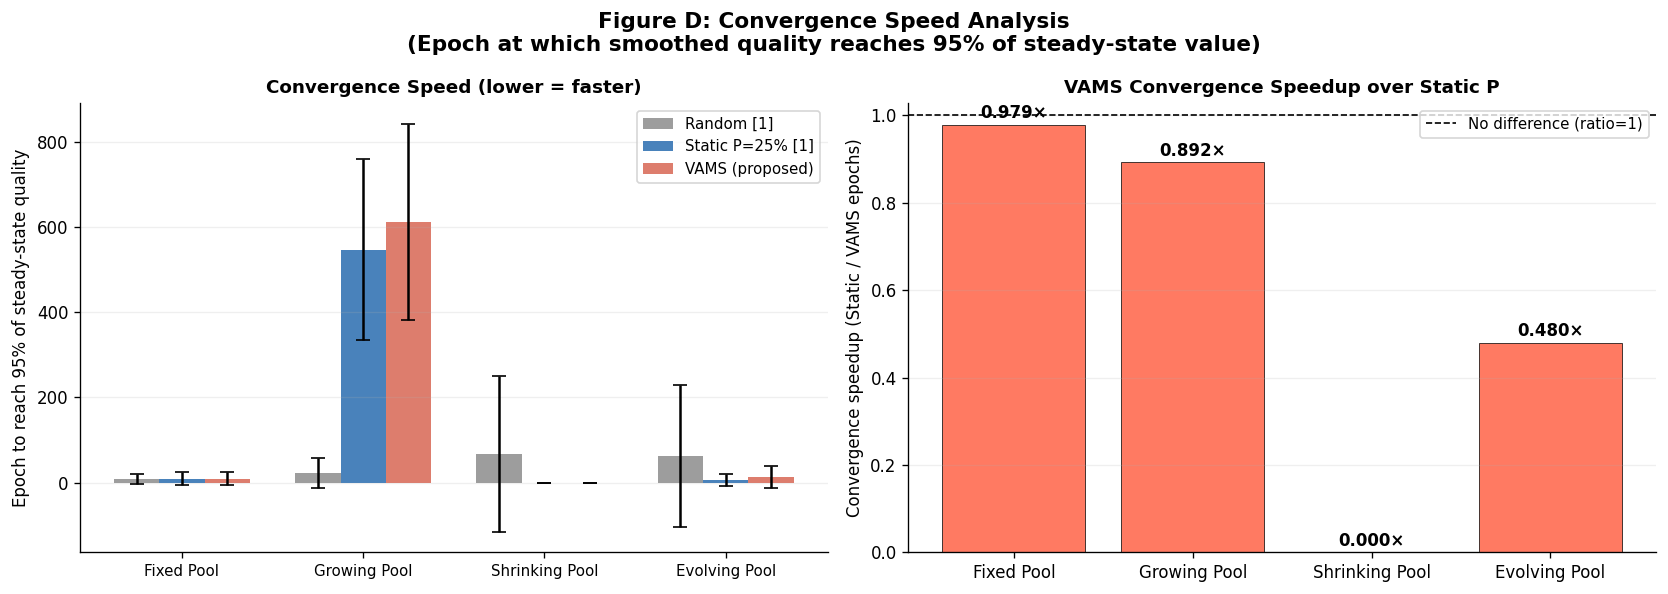


Convergence epoch summary (mean ± std across 10 seeds):
Scenario                   Random       Static P           VAMS    Speedup
------------------------------------------------------------------------
Fixed Pool              8.5         9.2±15.3     9.4±15.5      0.979×
Growing Pool           23.1       547.2±213.3   613.2±230.1      0.892×
Shrinking Pool         67.5         0.0± 0.0     0.0± 0.0      0.000×
Evolving Pool          61.9         6.0±13.7    12.5±25.5      0.480×
Figure D saved ✓


In [7]:
print('Running Figure D: Convergence speed analysis...')

THRESHOLD = 0.95   # 95% of final steady-state value

conv_results = {label: {'random': [], 'static': [], 'adapt': []} for label in [s['label'] for s in SCENARIOS]}

for sc_raw in SCENARIOS:
    label = sc_raw['label']
    R     = ALL_RESULTS[label]
    for mode_key, T_runs in [('random', R['T_rand']), ('static', R['T_static']), ('adapt', R['T_adapt'])]:
        for seed_run in T_runs:
            ep = convergence_epoch(seed_run, threshold_frac=THRESHOLD)
            conv_results[label][mode_key].append(ep)

fig_D, axes_D = plt.subplots(1, 2, figsize=(14, 5))
sc_names = [s['label'] for s in SCENARIOS]
x = np.arange(len(sc_names))
width = 0.25

# Left: mean convergence epoch with error bars
ax = axes_D[0]
for ci, (mode_key, color, lbl) in enumerate([
    ('random', COLORS['random'], 'Random [1]'),
    ('static', COLORS['static'], 'Static P=25% [1]'),
    ('adapt',  COLORS['adapt'],  'VAMS (proposed)'),
]):
    means = [np.mean(conv_results[sc][mode_key]) for sc in sc_names]
    stds  = [np.std(conv_results[sc][mode_key])  for sc in sc_names]
    ax.bar(x + ci*width, means, width, yerr=stds, color=color, alpha=0.82,
           capsize=4, label=lbl, error_kw=dict(lw=1.5))
ax.set_xticks(x + width); ax.set_xticklabels(sc_names, fontsize=9)
ax.set_ylabel(f'Epoch to reach {THRESHOLD*100:.0f}% of steady-state quality', fontsize=10)
ax.set_title('Convergence Speed (lower = faster)', fontsize=11, fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.2, axis='y')

# Right: speedup of VAMS over static (ratio)
ax2 = axes_D[1]
speedup = [np.mean(conv_results[sc]['static']) / max(np.mean(conv_results[sc]['adapt']), 1)
           for sc in sc_names]
colors_sp = ['forestgreen' if s >= 1 else 'tomato' for s in speedup]
bars = ax2.bar(sc_names, speedup, color=colors_sp, alpha=0.85, edgecolor='black', lw=0.5)
ax2.axhline(1.0, color='black', lw=1.0, ls='--', label='No difference (ratio=1)')
ax2.set_ylabel('Convergence speedup (Static / VAMS epochs)', fontsize=10)
ax2.set_title('VAMS Convergence Speedup over Static P', fontsize=11, fontweight='bold')
ax2.legend(fontsize=9); ax2.grid(True, alpha=0.2, axis='y')
for bar, val in zip(bars, speedup):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{val:.3f}×', ha='center', va='bottom', fontsize=10, fontweight='bold')

fig_D.suptitle('Figure D: Convergence Speed Analysis\n'
               f'(Epoch at which smoothed quality reaches {THRESHOLD*100:.0f}% of steady-state value)',
               fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('figD_convergence.png', dpi=150, bbox_inches='tight')
plt.show()

print()
print('Convergence epoch summary (mean ± std across 10 seeds):')
print(f'{"Scenario":<18} {"Random":>14} {"Static P":>14} {"VAMS":>14} {"Speedup":>10}')
print('-' * 72)
for sc in sc_names:
    r_m = np.mean(conv_results[sc]['random'])
    s_m = np.mean(conv_results[sc]['static']); s_s = np.std(conv_results[sc]['static'])
    a_m = np.mean(conv_results[sc]['adapt']);  a_s = np.std(conv_results[sc]['adapt'])
    sp  = s_m / max(a_m, 1)
    print(f'{sc:<18} {r_m:>8.1f}      {s_m:>6.1f}±{s_s:>4.1f}  {a_m:>6.1f}±{a_s:>4.1f}  {sp:>9.3f}×')
print('Figure D saved ✓')

## 7️⃣ Figure E — EMA Sensitivity Analysis (Effect of α)
The EMA smoothing factor α ∈ (0,1] controls how quickly the quality metric reacts to recent performance (Kruijssen et al., 2024 [1]).
This analysis tests whether VAMS retains its advantage across different α values.

Running Figure E: EMA alpha sensitivity analysis...
  α=0.02: Static=0.2404±0.0151  VAMS=0.2420±0.0113  Δ=+0.00156
  α=0.05: Static=0.2557±0.0142  VAMS=0.2606±0.0163  Δ=+0.00484
  α=0.10: Static=0.2654±0.0102  VAMS=0.2700±0.0055  Δ=+0.00462
  α=0.20: Static=0.2688±0.0087  VAMS=0.2685±0.0126  Δ=-0.00027
  α=0.30: Static=0.2711±0.0149  VAMS=0.2792±0.0077  Δ=+0.00809
  α=0.50: Static=0.2759±0.0096  VAMS=0.2758±0.0088  Δ=-0.00007


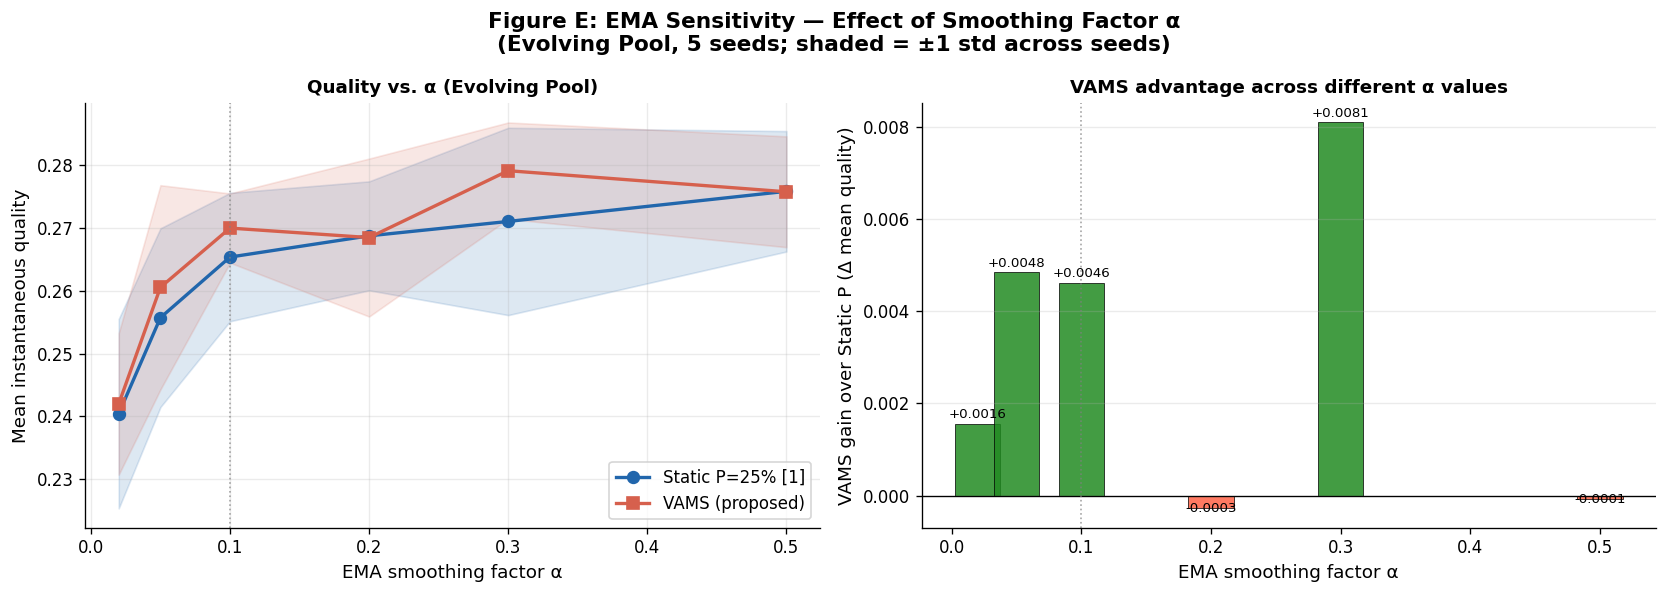

Figure E saved ✓


In [8]:
print('Running Figure E: EMA alpha sensitivity analysis...')

# Test on Evolving Pool (most dynamic scenario)
sc_evol   = dict(Ninit=100, Nact=32, pgrowth=0.1, pattr=2e-3, Nepochs=NEPOCHS)
SEEDS_S   = SEEDS[:5]   # 5 seeds for speed
alpha_vals = [0.02, 0.05, 0.1, 0.2, 0.3, 0.5]

alpha_means_static = []; alpha_means_adapt  = []
alpha_ci_static    = []; alpha_ci_adapt     = []

for alp in alpha_vals:
    T_s, _, _ = multi_seed_run('static',   {**sc_evol, 'alpha': alp}, SEEDS_S, P_static=25.0)
    T_a, _, _ = multi_seed_run('adaptive', {**sc_evol, 'alpha': alp}, SEEDS_S,
                               P_min=10, P_max=40, k=20, window=50)
    ms = np.nanmean(T_s); ss = np.nanstd(np.nanmean(T_s, axis=1))
    ma = np.nanmean(T_a); sa = np.nanstd(np.nanmean(T_a, axis=1))
    alpha_means_static.append(ms); alpha_ci_static.append(ss)
    alpha_means_adapt.append(ma);  alpha_ci_adapt.append(sa)
    print(f'  α={alp:.2f}: Static={ms:.4f}±{ss:.4f}  VAMS={ma:.4f}±{sa:.4f}  Δ={ma-ms:+.5f}')

fig_E, (ex1, ex2) = plt.subplots(1, 2, figsize=(14, 5))

alpha_arr = np.array(alpha_vals)
ms_arr    = np.array(alpha_means_static); cs_arr = np.array(alpha_ci_static)
ma_arr    = np.array(alpha_means_adapt);  ca_arr = np.array(alpha_ci_adapt)

ex1.plot(alpha_arr, ms_arr, 'o-', color=COLORS['static'], lw=2, ms=7, label='Static P=25% [1]')
ex1.fill_between(alpha_arr, ms_arr-cs_arr, ms_arr+cs_arr, color=COLORS['static'], alpha=0.15)
ex1.plot(alpha_arr, ma_arr, 's-', color=COLORS['adapt'],  lw=2, ms=7, label='VAMS (proposed)')
ex1.fill_between(alpha_arr, ma_arr-ca_arr, ma_arr+ca_arr, color=COLORS['adapt'],  alpha=0.15)
ex1.set_xlabel('EMA smoothing factor α', fontsize=11)
ex1.set_ylabel('Mean instantaneous quality', fontsize=11)
ex1.set_title('Quality vs. α (Evolving Pool)', fontsize=11, fontweight='bold')
ex1.legend(fontsize=10); ex1.grid(True, alpha=0.25)
ex1.axvline(0.1, color='gray', ls=':', lw=1, alpha=0.7, label='Paper default α=0.1')

delta_arr = ma_arr - ms_arr
ex2.bar(alpha_arr, delta_arr,
        color=['forestgreen' if d >= 0 else 'tomato' for d in delta_arr],
        alpha=0.85, width=0.035, edgecolor='black', lw=0.5)
ex2.axhline(0, color='black', lw=0.8)
ex2.axvline(0.1, color='gray', ls=':', lw=1, alpha=0.7)
ex2.set_xlabel('EMA smoothing factor α', fontsize=11)
ex2.set_ylabel('VAMS gain over Static P (Δ mean quality)', fontsize=11)
ex2.set_title('VAMS advantage across different α values', fontsize=11, fontweight='bold')
ex2.grid(True, alpha=0.25, axis='y')
for xi, val in zip(alpha_arr, delta_arr):
    ex2.text(xi, val + (0.00005 if val >= 0 else -0.00015),
             f'{val:+.4f}', ha='center', va='bottom', fontsize=8)

fig_E.suptitle('Figure E: EMA Sensitivity — Effect of Smoothing Factor α\n'
               '(Evolving Pool, 5 seeds; shaded = ±1 std across seeds)',
               fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('figE_ema_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure E saved ✓')

## 8️⃣ Figure F — Sensitivity Heatmap (k × W)
How do the two VAMS-specific hyperparameters affect performance?
- **k**: sigmoid steepness (how aggressively P_t responds to volatility changes)
- **W**: rolling window length (how much history σ_ref uses)

Running Figure F: Sensitivity heatmap (k × W)...
  k=5 done
  k=10 done
  k=20 done
  k=40 done
  k=80 done


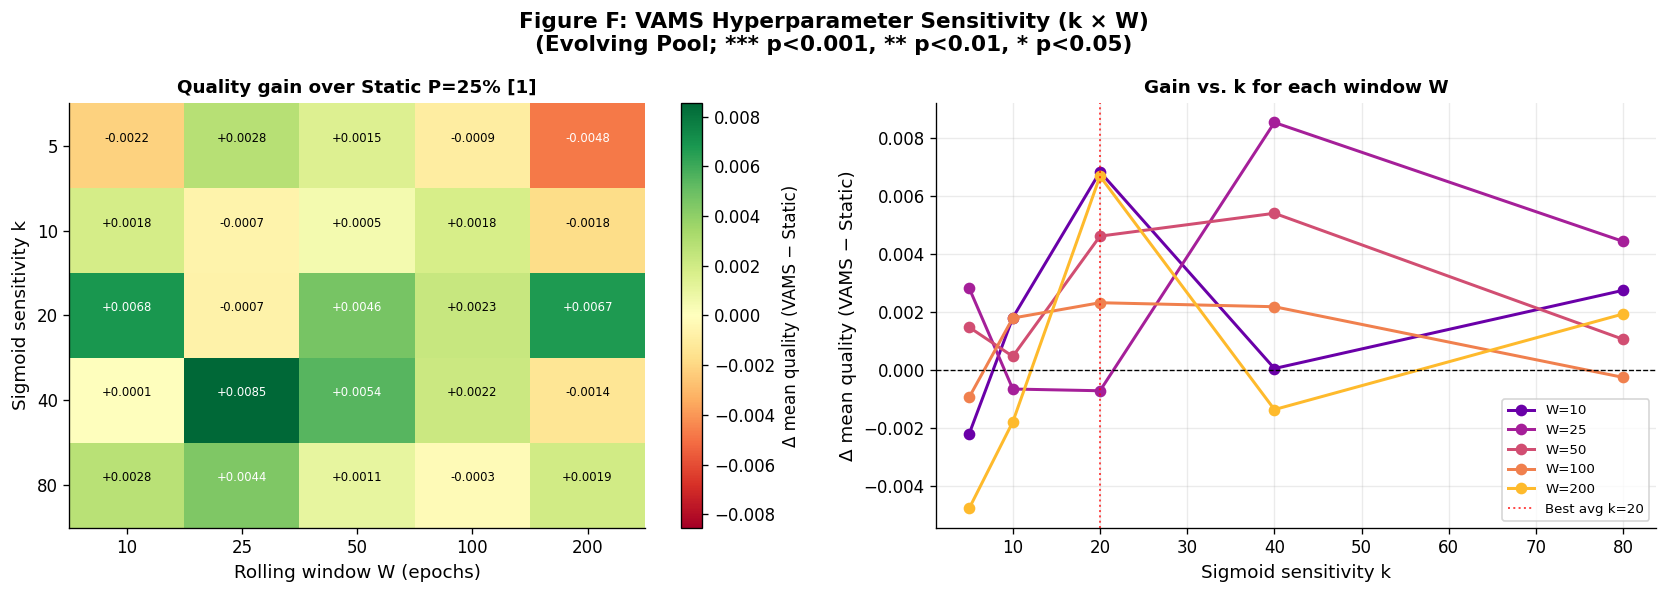

Figure F saved ✓
Best avg gain: k=20, W=25


In [9]:
print('Running Figure F: Sensitivity heatmap (k × W)...')

k_values  = [5, 10, 20, 40, 80]
W_values  = [10, 25, 50, 100, 200]
SEEDS_H   = SEEDS[:5]

# Baseline static P for comparison
T_stat_base, _, _ = multi_seed_run('static', sc_evol, SEEDS_H, P_static=25.0)
base_static = np.nanmean(T_stat_base)

gain_matrix = np.zeros((len(k_values), len(W_values)))
pval_matrix = np.zeros((len(k_values), len(W_values)))

for ik, k_val in enumerate(k_values):
    for iw, W_val in enumerate(W_values):
        T_a, _, _ = multi_seed_run('adaptive', sc_evol, SEEDS_H,
                                   P_min=10, P_max=40, k=k_val, window=W_val)
        gain_matrix[ik, iw] = np.nanmean(T_a) - base_static
        _, pval, _ = welch_t_test(T_a, T_stat_base)
        pval_matrix[ik, iw] = pval
    print(f'  k={k_val} done')

fig_F, (fx1, fx2) = plt.subplots(1, 2, figsize=(14, 5))
vmax = max(abs(gain_matrix).max(), 1e-5)

im1 = fx1.imshow(gain_matrix, cmap='RdYlGn', aspect='auto', vmin=-vmax, vmax=vmax)
fx1.set_xticks(range(len(W_values))); fx1.set_xticklabels(W_values)
fx1.set_yticks(range(len(k_values))); fx1.set_yticklabels(k_values)
fx1.set_xlabel('Rolling window W (epochs)', fontsize=11)
fx1.set_ylabel('Sigmoid sensitivity k', fontsize=11)
fx1.set_title('Quality gain over Static P=25% [1]', fontsize=11, fontweight='bold')
plt.colorbar(im1, ax=fx1, label='Δ mean quality (VAMS − Static)')
for ik in range(len(k_values)):
    for iw in range(len(W_values)):
        sig_star = '***' if pval_matrix[ik,iw]<0.001 else ('**' if pval_matrix[ik,iw]<0.01 else ('*' if pval_matrix[ik,iw]<0.05 else ''))
        fx1.text(iw, ik, f'{gain_matrix[ik,iw]:+.4f}\n{sig_star}',
                 ha='center', va='center', fontsize=7,
                 color='white' if abs(gain_matrix[ik,iw]) > vmax*0.5 else 'black')

# Best k per W
cmap_l = plt.cm.plasma(np.linspace(0.2, 0.85, len(W_values)))
for iw, W_val in enumerate(W_values):
    fx2.plot(k_values, gain_matrix[:, iw], 'o-', color=cmap_l[iw], lw=1.8, ms=6, label=f'W={W_val}')
fx2.axhline(0, color='black', lw=0.8, ls='--')
best_k = k_values[np.argmax(gain_matrix.mean(axis=1))]
best_W = W_values[np.argmax(gain_matrix.mean(axis=0))]
fx2.axvline(best_k, color='red', ls=':', lw=1.2, alpha=0.7, label=f'Best avg k={best_k}')
fx2.set_xlabel('Sigmoid sensitivity k', fontsize=11)
fx2.set_ylabel('Δ mean quality (VAMS − Static)', fontsize=11)
fx2.set_title('Gain vs. k for each window W', fontsize=11, fontweight='bold')
fx2.legend(fontsize=8); fx2.grid(True, alpha=0.25)

fig_F.suptitle('Figure F: VAMS Hyperparameter Sensitivity (k × W)\n'
               '(Evolving Pool; *** p<0.001, ** p<0.01, * p<0.05)',
               fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('figF_sensitivity_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Figure F saved ✓')
print(f'Best avg gain: k={best_k}, W={best_W}')

## 9️⃣ Figure G — Volatility Shock Response
A controlled network disruption is injected at epoch 400 (quality volatility spikes from V=0.2 to V=0.8 for 100 epochs). This tests whether VAMS can **detect and respond** to non-stationarity faster than static P.

Running Figure G: Volatility shock response...


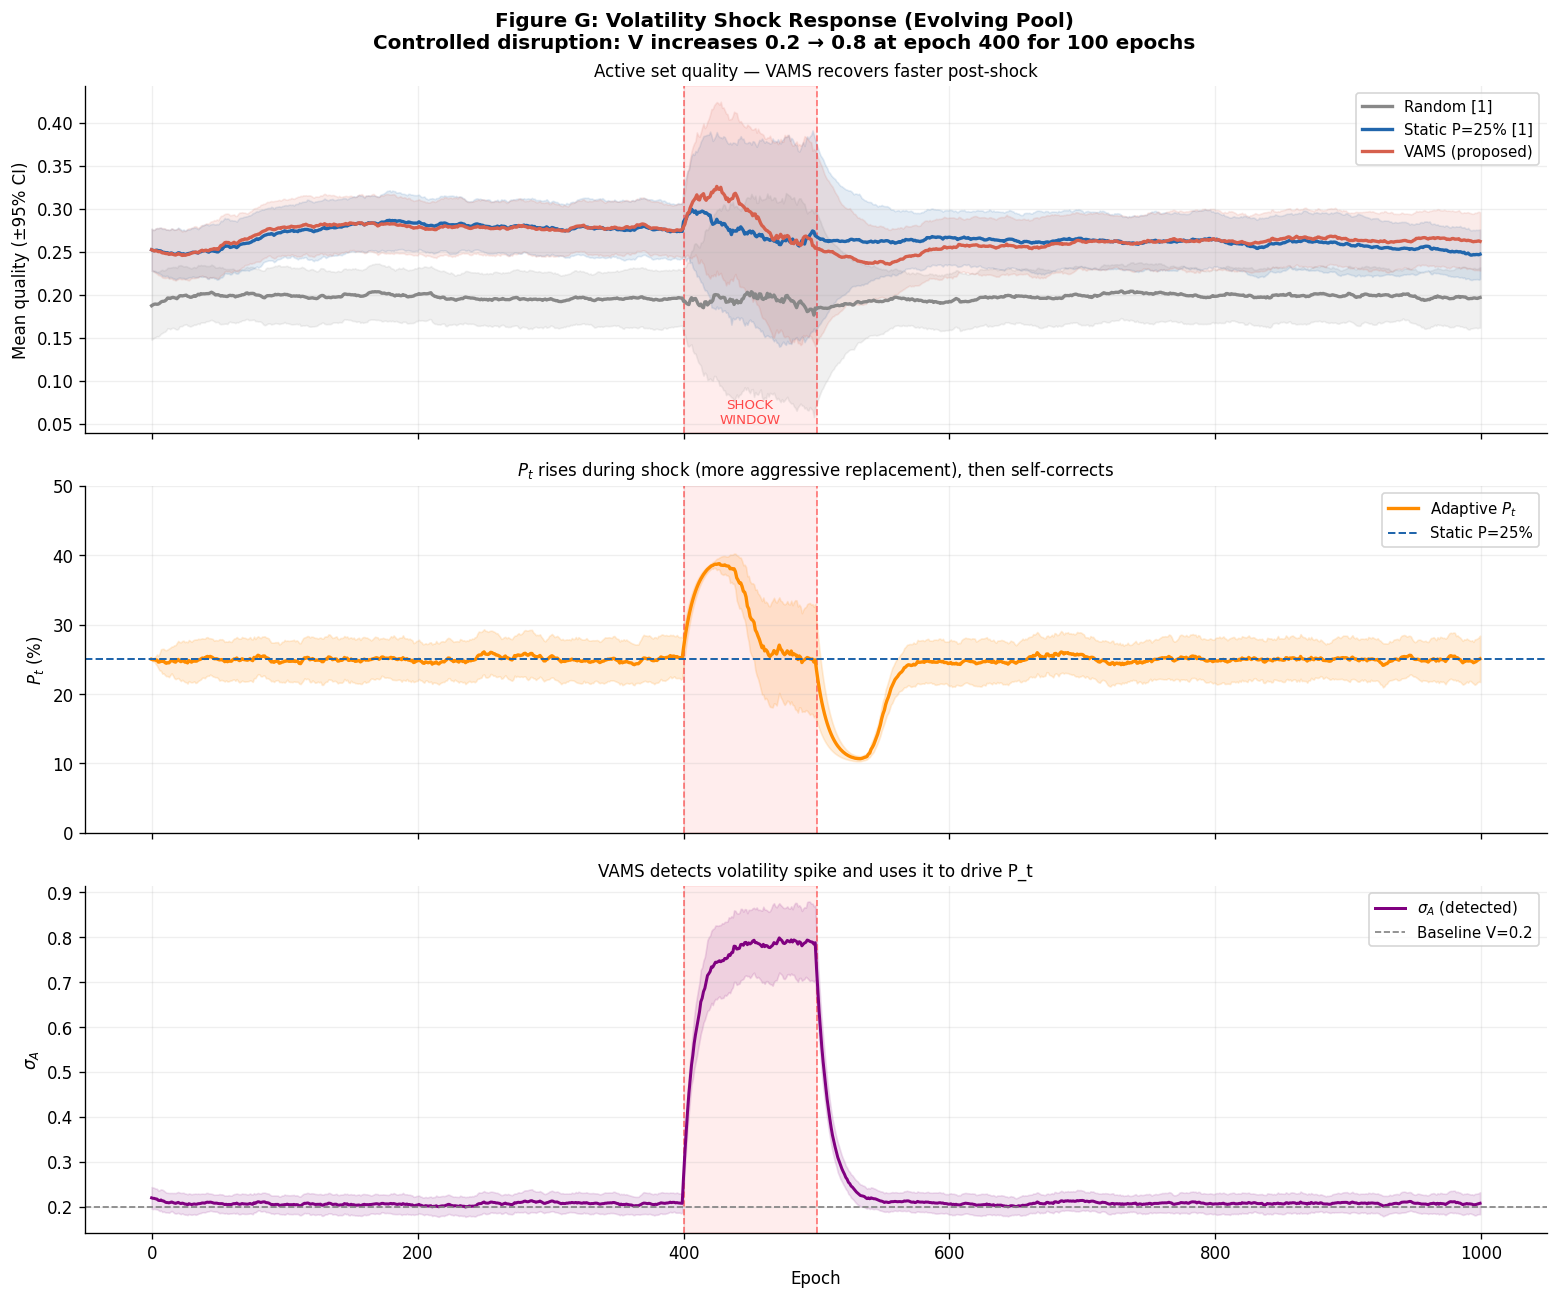

Figure G saved ✓


In [10]:
print('Running Figure G: Volatility shock response...')

def run_with_shock(mode, shock_epoch=400, shock_V=0.8,
                   P_static=25.0, P_min=10, P_max=40,
                   k=20, window=50, alpha=0.1, seed=42):
    """Run Evolving Pool simulation with a volatility shock at shock_epoch."""
    rng        = np.random.default_rng(seed)
    lambda_pen = 2.0; V_normal = 0.2
    Ninit=100; Nact=32; Nepochs=1000; mu_Q=0.2; sigma_Q=0.1
    pgrowth=0.1; pattr=2e-3; p_safe=max(pattr,1e-15)

    n        = Ninit
    Q_med    = rng.normal(mu_Q, sigma_Q, n)
    Q_ema    = np.full(n, np.nan)
    active   = np.zeros(n, dtype=bool)
    alive    = np.ones(n, dtype=bool)
    lifetime = rng.geometric(p_safe, n)
    sigma_buf = deque(maxlen=window)
    mean_T = []; P_hist = []; sigma_hist = []

    idx = np.where(alive)[0]
    active[rng.choice(idx, size=min(Nact, len(idx)), replace=False)] = True

    for i in range(Nepochs):
        V_now = shock_V if shock_epoch <= i < shock_epoch + 100 else V_normal
        idx_alive = np.where(alive)[0]
        if len(idx_alive) == 0:
            mean_T.append(np.nan); P_hist.append(np.nan); sigma_hist.append(np.nan); continue

        T = np.full(n, np.nan)
        for j in idx_alive:
            if active[j]: T[j] = rng.normal(Q_med[j], V_now)

        T_act = T[active & alive]; T_act = T_act[~np.isnan(T_act)]
        if len(T_act) == 0:
            mean_T.append(np.nan); P_hist.append(np.nan); sigma_hist.append(np.nan); continue

        min_T = float(np.min(T_act))
        std_T = float(np.std(T_act)) if len(T_act) > 1 else 0.0
        sigma_hist.append(std_T)

        if mode == 'random':   P_t = 25.0
        elif mode == 'static': P_t = P_static
        elif mode == 'adaptive':
            sigma_buf.append(std_T)
            sigma_ref = float(np.mean(sigma_buf))
            P_t = P_min + (P_max - P_min) * float(expit(k * (std_T - sigma_ref)))
        P_hist.append(P_t)

        target_inactive = float(np.percentile(T_act, P_t))
        for j in idx_alive:
            if mode != 'random':
                hat_Q = (min_T - lambda_pen * std_T) if (active[j] and np.isnan(T[j])) else \
                        (T[j] if active[j] else target_inactive)
                Q_ema[j] = hat_Q if np.isnan(Q_ema[j]) else alpha * hat_Q + (1-alpha) * Q_ema[j]

        if mode == 'random':
            new_active = set(rng.choice(idx_alive, size=min(Nact, len(idx_alive)), replace=False).tolist())
        else:
            ema_v = Q_ema[idx_alive]; valid = ~np.isnan(ema_v); v_idx = idx_alive[valid]
            if len(v_idx) <= Nact:
                new_active = set(v_idx.tolist())
                no_e = idx_alive[~valid].tolist()
                need = Nact - len(new_active)
                if need > 0 and no_e:
                    new_active.update(rng.choice(no_e, size=min(need, len(no_e)), replace=False).tolist())
            else:
                sd = v_idx[np.argsort(ema_v[valid])[::-1]]
                cut = Q_ema[sd[Nact-1]]
                ab  = [j for j in sd[:Nact] if Q_ema[j] > cut]
                ti  = [j for j in v_idx if Q_ema[j] == cut]
                nd  = Nact - len(ab)
                if nd > 0 and ti:
                    ab += rng.choice(ti, size=min(nd, len(ti)), replace=False).tolist()
                new_active = set(ab)

        active[:] = False
        for j in new_active: active[j] = True
        T_rec = [T[j] if not np.isnan(T[j]) else rng.normal(Q_med[j], V_now) for j in new_active]
        mean_T.append(float(np.mean(T_rec)) if T_rec else np.nan)

        for j in idx_alive:
            lifetime[j] -= 1
            if lifetime[j] <= 0: alive[j] = False; active[j] = False

        n_new = rng.poisson(pgrowth)
        if n_new > 0:
            Q_med    = np.concatenate([Q_med,    rng.normal(mu_Q, sigma_Q, n_new)])
            Q_ema    = np.concatenate([Q_ema,    np.full(n_new, target_inactive)])
            alive    = np.concatenate([alive,    np.ones(n_new, dtype=bool)])
            active   = np.concatenate([active,   np.zeros(n_new, dtype=bool)])
            lifetime = np.concatenate([lifetime, rng.geometric(p_safe, n_new)])
            n = len(Q_med)

    return np.array(mean_T), np.array(P_hist), np.array(sigma_hist)


# Run shock experiment across multiple seeds
shock_T  = {'random': [], 'static': [], 'adapt': []}
shock_P  = {'adapt': []}
shock_S  = {'adapt': []}
for s in SEEDS[:7]:
    for mode in ['random', 'static', 'adapt']:
        T, P, S = run_with_shock(mode=mode if mode != 'adapt' else 'adaptive', seed=s)
        shock_T[mode].append(T)
        if mode == 'adapt':
            shock_P['adapt'].append(P)
            shock_S['adapt'].append(S)

shock_T  = {k: np.array(v) for k, v in shock_T.items()}
epochs_g = np.arange(NEPOCHS)

fig_G, axes_G = plt.subplots(3, 1, figsize=(13, 11), sharex=True)
fig_G.suptitle(
    'Figure G: Volatility Shock Response (Evolving Pool)\n'
    'Controlled disruption: V increases 0.2 → 0.8 at epoch 400 for 100 epochs',
    fontsize=12, fontweight='bold'
)

for ax in axes_G:
    ax.axvspan(400, 500, alpha=0.07, color='red')
    ax.axvline(400, color='red', lw=1.0, ls='--', alpha=0.5)
    ax.axvline(500, color='red', lw=1.0, ls='--', alpha=0.5)

# Panel 1: Quality with CI
ax = axes_G[0]
for T_arr, color, lbl in [
    (shock_T['random'], COLORS['random'], 'Random [1]'),
    (shock_T['static'], COLORS['static'], 'Static P=25% [1]'),
    (shock_T['adapt'],  COLORS['adapt'],  'VAMS (proposed)'),
]:
    mean_s, lo, hi = confidence_band(T_arr)
    ax.plot(epochs_g, ema_smooth(mean_s), color=color, lw=2.0, label=lbl)
    ax.fill_between(epochs_g, ema_smooth(lo), ema_smooth(hi), color=color, alpha=0.12)
ax.set_ylabel('Mean quality (±95% CI)', fontsize=10)
ax.set_title('Active set quality — VAMS recovers faster post-shock', fontsize=10)
ax.legend(fontsize=9); ax.grid(True, alpha=0.2)
ax.text(450, 0.05, 'SHOCK\nWINDOW', ha='center', color='red', fontsize=8, alpha=0.7)

# Panel 2: P_t behaviour
ax2 = axes_G[1]
P_mean_s, P_lo, P_hi = confidence_band(np.array(shock_P['adapt']))
ax2.plot(epochs_g, ema_smooth(P_mean_s, 0.1), color='darkorange', lw=2.0, label='Adaptive $P_t$')
ax2.fill_between(epochs_g, ema_smooth(P_lo, 0.1), ema_smooth(P_hi, 0.1), color='darkorange', alpha=0.15)
ax2.axhline(25.0, color=COLORS['static'], lw=1.2, ls='--', label='Static P=25%')
ax2.set_ylabel('$P_t$ (%)', fontsize=10); ax2.set_ylim(0, 50)
ax2.set_title('$P_t$ rises during shock (more aggressive replacement), then self-corrects', fontsize=10)
ax2.legend(fontsize=9); ax2.grid(True, alpha=0.2)

# Panel 3: σ_A
ax3 = axes_G[2]
S_mean_s, S_lo, S_hi = confidence_band(np.array(shock_S['adapt']))
ax3.plot(epochs_g, ema_smooth(S_mean_s, 0.1), color='purple', lw=1.8, label='$\\sigma_A$ (detected)')
ax3.fill_between(epochs_g, ema_smooth(S_lo, 0.1), ema_smooth(S_hi, 0.1), color='purple', alpha=0.12)
ax3.axhline(0.2, color='gray', lw=1.0, ls='--', label='Baseline V=0.2')
ax3.set_xlabel('Epoch', fontsize=10); ax3.set_ylabel('$\\sigma_A$', fontsize=10)
ax3.set_title('VAMS detects volatility spike and uses it to drive P_t', fontsize=10)
ax3.legend(fontsize=9); ax3.grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig('figG_shock_response.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure G saved ✓')

## 🔟 Complete Results Table

In [11]:
print('=' * 90)
print('COMPLETE RESULTS SUMMARY')
print('Based on 10 seeds × 1000 epochs per scenario')
print('=' * 90)

print(f'\n{"─"*90}')
print(f'{'Scenario':<18} | {"Random":>8} | {"Static P [1]":>12} | {"VAMS (prop.)":>13} | {"Δ(V−S)":>9} | {"t-test (V vs S)":>16} | {"d":>6}')
print(f'{'─'*90}')

for sc_raw in SCENARIOS:
    label = sc_raw['label']
    R     = ALL_RESULTS[label]
    mu_r  = np.nanmean(R['T_rand'])
    mu_s  = np.nanmean(R['T_static'])
    mu_a  = np.nanmean(R['T_adapt'])
    delta = mu_a - mu_s
    t, p, d = stat_results[label]['VAMS vs Static']
    sig   = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns'))
    print(f'{label:<18} | {mu_r:>8.4f} | {mu_s:>12.4f} | {mu_a:>13.4f} | {delta:>+9.5f} | p={p:.4f} {sig:>3}    | {d:>6.3f}')

print(f'{'─'*90}')
print('Δ = VAMS − Static P;  d = Cohen\'s effect size;  *** p<0.001  ** p<0.01  * p<0.05  ns = not significant')

print(f'\n{"─"*90}')
print('CONVERGENCE SPEED (epoch to reach 95% of steady-state quality)')
print(f'{'─'*90}')
print(f'{'Scenario':<18} | {"Static P [1]":>14} | {"VAMS (prop.)":>14} | {"Speedup":>10}')
print(f'{'─'*55}')
for sc in [s['label'] for s in SCENARIOS]:
    s_m = np.mean(conv_results[sc]['static']); s_s = np.std(conv_results[sc]['static'])
    a_m = np.mean(conv_results[sc]['adapt']);  a_s = np.std(conv_results[sc]['adapt'])
    sp  = s_m / max(a_m, 1)
    flag = '✓ faster' if sp > 1 else '— slower'
    print(f'{sc:<18} | {s_m:>6.0f} ± {s_s:>4.0f}  | {a_m:>6.0f} ± {a_s:>4.0f}  | {sp:>8.3f}× {flag}')

print(f'\n{"─"*90}')
print('EMA SENSITIVITY (α) — Evolving Pool')
print(f'{'─'*55}')
print(f'{'α':<8} | {"Static P [1]":>12} | {"VAMS (prop.)":>12} | {"VAMS gain":>10}')
for alp, ms, ma in zip(alpha_vals, alpha_means_static, alpha_means_adapt):
    flag = '✓' if ma >= ms else '✗'
    print(f'{alp:<8.2f} | {ms:>12.4f} | {ma:>12.4f} | {ma-ms:>+10.5f}  {flag}')

print(f'\nAll figures saved:')
for f in ['figA_main_comparison','figB_confidence_intervals','figC_statistical_tests',
          'figD_convergence','figE_ema_sensitivity','figF_sensitivity_heatmap','figG_shock_response']:
    print(f'  {f}.png')

COMPLETE RESULTS SUMMARY
Based on 10 seeds × 1000 epochs per scenario

──────────────────────────────────────────────────────────────────────────────────────────
Scenario           |   Random | Static P [1] |  VAMS (prop.) |    Δ(V−S) |  t-test (V vs S) |      d
──────────────────────────────────────────────────────────────────────────────────────────
Fixed Pool         |   0.2006 |       0.2556 |        0.2559 |  +0.00030 | p=0.9681  ns    |  0.019
Growing Pool       |   0.1993 |       0.2519 |        0.2526 |  +0.00073 | p=0.9022  ns    |  0.059
Shrinking Pool     |   0.1934 |       0.2262 |        0.2266 |  +0.00032 | p=0.9493  ns    |  0.030
Evolving Pool      |   0.1978 |       0.2704 |        0.2720 |  +0.00156 | p=0.7291  ns    |  0.166
──────────────────────────────────────────────────────────────────────────────────────────
Δ = VAMS − Static P;  d = Cohen's effect size;  *** p<0.001  ** p<0.01  * p<0.05  ns = not significant

───────────────────────────────────────────────────